# Criteo: 데이터 이해 → 새 가설 → 독립 표본 검증

이 노트북은 기존 12만 명 실습과 **별도인 새 100만 행**을 사용합니다. 이전 H1/H2의 판단 보류 결과는 `experiments/02_criteo/archive/baseline_results`와 `experiments/02_criteo/results/previous_experiments/02_criteo/study.ipynb`에 남깁니다. 가설을 덮어쓰지 않고 **H3/H4**로 새 실험을 기록합니다.

각 단계는 **① 질문·가설 → ② 원리와 구현 → ③ 결과 → ④ 판정·한계** 순서입니다. 과거 성과를 본 고객은 모두 제외합니다. 새 표본은 특성만으로 Discovery/Train/Validation/Test에 약 20/40/10/30% 배정하며, 같은 익명 특성 프로필은 분할을 넘지 않습니다. `row_id`는 파일 행 번호이며 실제 고객 식별자가 아닙니다.

## 이 데이터가 답할 수 있는 질문

- 공개본은 광고 타기팅 **배정** `treatment`와 방문 `visit`, 전환 `conversion`, 실제 노출 `exposure`를 포함합니다. 배정 효과와 실제 노출 효과는 다릅니다. exposure는 감사용으로만 보고 피처·처치 대용으로 사용하지 않습니다.
- 정정판 논문은 **f0/f2/f7/f10은 연속형, 나머지 8개는 익명 범주형**이라고 설명합니다. 실수 dtype을 변수 의미와 혼동하지 않습니다. 파일의 실제 고유값 수와 빈도를 대조합니다.
- 여러 광고주 실험을 합쳤고 결과 의존 negative sampling이 적용됐습니다. 원 모집단의 ATE·원 광고주의 매출·ROAS를 복원할 수 없습니다. 아래 인과 추정은 공개표본에서의 교환가능성·일관성·positivity를 추가로 가정한 **벤치마크 비교**입니다. 이 가정이 확인된 사실은 아닙니다.
- 공식 설명은 논문 v2와 파일 v2.1의 세부 변경 이력을 완전히 제공하지 않습니다. revision을 고정하고 실제 파일을 검증합니다. 익명 피처를 나이·소득 등으로 임의 해석하지 않습니다.

출처: [정정판 논문 §3](https://arxiv.org/html/2111.10106#S3), [검증·실험 §5](https://arxiv.org/html/2111.10106#S5), [공식 정정·Privacy](https://ailab.criteo.com/criteo-uplift-prediction-dataset/), [HF 카드](https://huggingface.co/datasets/criteo/criteo-uplift).

## 제공 실습자료와의 대응

| 제공 노트북 코드 | 이번 적용 |
|---|---|
| 결과 회귀·반사실 예측 | 선형 결과 회귀와 T별 결과 예측 |
| LogisticRegression → 역확률 가중 회귀 | 공개표본 propensity를 학습한 IPW와 가중 회귀 |
| DoWhy Model → Identify → Estimate → Refute | 명시적 backdoor 가정·선형 추정·위약 처치 |
| S/T/X Meta-Learner | 같은 분할·학습 설정으로 수치형/범주형 표현 비교 |
| DML/DR-Learner | 프로필 단위 교차 적합 잔차·의사결과 |

참고 파일: `references/ML_for_Causal_Inference.ipynb`. 기본 ML은 자료의 RandomForest 대신 대용량 범주형 지원 HistGradientBoosting으로 바꾸고, S/T/X·DR/DML 수식은 `shared/criteo/models.py`에서 직접 확인할 수 있도록 구현했습니다. EconML을 호출했다는 의미는 아닙니다.

## STEP 0. 실행 환경
### ① 질문
다른 노트북을 실행하지 않아도 같은 원본·표본·설정에서 결과를 재현할 수 있는가?
### ② 구현
프로젝트 루트와 `.venv` 커널에서 실행합니다. 설치는 `uv pip install --python .venv/bin/python -r requirements.txt`. 최초 로드는 원본을 두 번 스캔하고 약 수십 MB의 압축 표본 캐시를 만들며 이후에는 캐시를 검증해 재사용합니다. 대용량 원본의 압축 해제본은 만들지 않습니다.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS','2')
os.environ.setdefault('OPENBLAS_NUM_THREADS','2')
from pathlib import Path
import sys,json,hashlib,importlib.metadata as metadata
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from dowhy import CausalModel
ROOT=next(p for p in (Path.cwd(), *Path.cwd().parents)
          if (p/'shared'/'causal_utils.py').is_file())
sys.path.insert(0,str(ROOT))
from shared.criteo.study import load_fresh
from shared.criteo.models import (FEATURES,CONTINUOUS_FEATURES,CATEGORICAL_FEATURES,
    CriteoFeatureEncoder,fit_candidates,fit_outcomes,fit_crossfit_dr)
from shared.criteo.inference import policy_stats,bootstrap,verdict
SEED=20261111
N_SAMPLE=1_000_000
B=399
K=.30
DATA=ROOT/'data/criteo'
OUT=ROOT/'experiments/02_criteo/results'
OUT.mkdir(parents=True,exist_ok=True)
VERSIONS={p:metadata.version(p) for p in ['numpy','pandas','scikit-learn','dowhy','nbformat','nbclient']}
MODEL_PARAMS=dict(max_iter=120,max_leaf_nodes=15,min_samples_leaf=200,
    learning_rate=.06,l2_regularization=2.,early_stopping=False,max_frequent_categories=63)
display(pd.Series(VERSIONS,name='실행 버전'))

/Users/hyeonee/local_workspace/causal_study/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


numpy            2.5.3
pandas           3.0.5
scikit-learn     1.9.1
dowhy             0.14
nbformat        5.11.1
nbclient        0.11.0
Name: 실행 버전, dtype: str

### ③ 결과·④ 판정
버전과 원본·표본 메타데이터를 출력합니다. 원본 SHA-256 불일치나 이전 표본과의 중복은 실행 실패로 처리합니다.

## STEP 1. 새 고객과 독립 평가 구조
### ① 질문
이전 Test를 보지 않은 새로운 검증을 할 수 있는가?
### ② 구현
이전 12만 행을 seed=42로 정확히 재구성해 제외한 뒤 전체 파일에서 처치군별 균등 priority sampling을 합니다. 새 표본의 처치 비율은 원본의 약 85%를 유지합니다. 특성 프로필 해시로 분할하므로 동일 프로필이 여러 구간에 들어가지 않습니다. 동일 프로필이 동일인이라는 뜻은 아니며 보수적인 분할입니다. 실제 고객/캠페인 ID와 시점이 없어 고객·캠페인·시간 단위의 독립성은 완전히 검증할 수 없습니다.

In [2]:
df,sampling=load_fresh(DATA,n=N_SAMPLE,seed=SEED,cache_dir=OUT/'cache')
profile=pd.util.hash_pandas_object(df[FEATURES],index=False).to_numpy()
bucket=profile%10000
partition=np.select([bucket<2000,bucket<6000,bucket<7000],['discovery','train','validation'],default='test')
idx={name:np.flatnonzero(partition==name) for name in ['discovery','train','validation','test']}
for a in idx:
    for b in idx:
        if a!=b: assert not np.intersect1d(profile[idx[a]],profile[idx[b]]).size
assert sampling['excluded_overlap']==0 and df.row_id.is_unique
assert not set(['exposure','visit','conversion','treatment','row_id']) & set(FEATURES)
assert df[['treatment','visit','conversion','exposure']].isin([0,1]).all().all()
d=idx['discovery'];tr=idx['train'];v=idx['validation']
T=df.treatment.to_numpy();Y=df.visit.to_numpy()
# No test outcome distribution or test scores are inspected before protocol freeze.
display(pd.DataFrame([{'partition':name,'rows':len(ids),
    'treatment_rate':float(T[ids].mean()) if name!='test' else np.nan} for name,ids in idx.items()]))
display(pd.Series(sampling))

,partition,rows,treatment_rate
0,discovery,199536,0.850052
1,train,400351,0.850471
2,validation,100060,0.849500
3,test,300053,NaN


cache_key                     criteo-fresh-v2-2716e1bf0fd157a9-sampler6d226a...
dataset                                                    criteo/criteo-uplift
source_file                                  criteo-research-uplift-v2.1.csv.gz
source_sha256                 2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6c...
revision                               2424920019e49d52d72c13ac1143ec5d53af276b
exclusion_sampler_sha256      6d226a322a4e48f6242a0e6001530f89a4e70fcb79452e...
seed                                                                   20261111
n                                                                       1000000
exclude_n                                                                120000
exclude_seed                                                                 42
excluded_row_id_sha256        38c556e784f1396c6544c5bf446a50706835cc193cd6be...
sample_row_id_sha256          9d16f0a4dad95c88f46dd1659985fec0b6b6974ae711cd...
population_counts                       

### ③ 결과·④ 판정
위 표에서 중복 0과 분할 크기를 확인합니다. 처치 비율은 표본 전체에서 보존하며 프로필 분할별 비율은 조금 달라질 수 있습니다. Test의 개별 성과·모델 점수는 아직 열지 않습니다.

## STEP 2. Discovery 전용 데이터 이해
### ① 탐색 질문
실수 열을 모두 연속형으로 보아도 되는가? 값이 특정 수준에 집중되는가? 방문·전환·노출 정의에 맞지 않는 기록이 있는가?
### ② 구현
Discovery 약 20만 행에서 고유값·최빈값 비중·결측·중복과 레이블 관계를 확인합니다. 반복되는 연속형 값은 0이나 결측으로 임의 변경하지 않습니다. 범주형 상위 빈도 63개를 보존하는 설계의 정보 손실도 확인합니다. 관찰된 그룹 차이는 가설 발굴용이며 다중 탐색 결과를 확증적 검정으로 해석하지 않습니다.

,type,unique,missing,nonfinite,top1_share,top63_coverage
f0,continuous,138941,0.0,False,0.264529,0.265641
f1,hashed_category,23,0.0,False,0.987877,1.000000
f2,continuous,91877,0.0,False,0.523860,0.524808
f3,hashed_category,276,0.0,False,0.819386,0.991941
f4,hashed_category,79,0.0,False,0.956264,0.999920
f5,hashed_category,50,0.0,False,0.946902,1.000000
f6,hashed_category,688,0.0,False,0.264529,0.948270
f7,continuous,10574,0.0,False,0.946902,0.947323
f8,hashed_category,1298,0.0,False,0.523860,0.918862
f9,hashed_category,581,0.0,False,0.794919,0.974050


visit                 conversion                exposure        \
            count   sum      mean      count  sum      mean    count   sum   
treatment                                                                    
0           29920  1109  0.037066      29920   51  0.001705    29920     0   
1          169616  8350  0.049229     169616  505  0.002977   169616  6079   

                    
              mean  
treatment           
0          0.00000  
1          0.03584

conversion,0,1
visit,,
0,190077,0
1,8903,556


Discovery duplicate-profile fraction: 0.010830125892069602
Exposure in controls: 0
Conversions with no visit: 0


,feature,group,n,control_events,control_rate,treated_rate,raw_gap
0,f1,mode,197117,1054,0.035582,0.046557,0.010975
1,f1,other,2419,55,0.184564,0.260255,0.075691
2,f3,mode,163497,664,0.026617,0.031079,0.004461
3,f3,other,36039,445,0.089465,0.130179,0.040713
4,f4,mode,190809,754,0.026302,0.036937,0.010635
5,f4,other,8727,355,0.283320,0.315895,0.032575
6,f5,mode,188941,948,0.033285,0.042970,0.009685
7,f5,other,10595,161,0.111883,0.158912,0.047029
8,f6,mode,52783,391,0.048254,0.056356,0.008103
9,f6,other,146753,718,0.032910,0.046680,0.013770


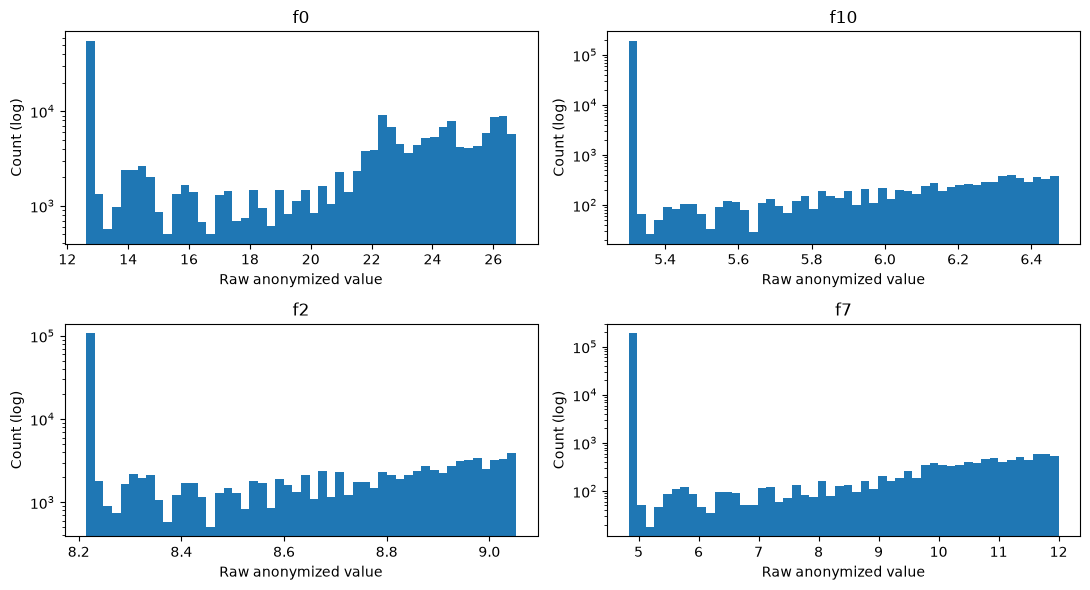

In [3]:
disc=df.iloc[d]
audit=pd.DataFrame({'type':['continuous' if f in CONTINUOUS_FEATURES else 'hashed_category' for f in FEATURES]},index=FEATURES)
audit['unique']=disc[FEATURES].nunique()
audit['missing']=disc[FEATURES].isna().mean()
audit['nonfinite']=~np.isfinite(disc[FEATURES]).all()
audit['top1_share']=disc[FEATURES].apply(lambda s:s.value_counts(normalize=True).iloc[0])
audit['top63_coverage']=disc[FEATURES].apply(lambda s:s.value_counts(normalize=True).head(63).sum())
display(audit)
event_table=disc.groupby('treatment')[['visit','conversion','exposure']].agg(['count','sum','mean'])
display(event_table)
display(pd.crosstab(disc.visit,disc.conversion))
print('Discovery duplicate-profile fraction:',disc.duplicated(FEATURES).mean())
print('Exposure in controls:',int(disc.loc[disc.treatment.eq(0),'exposure'].sum()))
print('Conversions with no visit:',int(((disc.conversion==1)&(disc.visit==0)).sum()))
mode_patterns=[]
for f in CATEGORICAL_FEATURES:
    mode=disc[f].mode().iloc[0]
    for label,mask in [('mode',disc[f].eq(mode)),('other',disc[f].ne(mode))]:
        g=disc.loc[mask];g0=g.loc[g.treatment.eq(0),'visit'];g1=g.loc[g.treatment.eq(1),'visit']
        mode_patterns.append({'feature':f,'group':label,'n':len(g),'control_events':g0.sum(),
                             'control_rate':g0.mean(),'treated_rate':g1.mean(),'raw_gap':g1.mean()-g0.mean()})
mode_patterns=pd.DataFrame(mode_patterns)
display(mode_patterns)
audit.to_csv(OUT/'discovery_feature_audit.csv')
event_table.to_csv(OUT/'discovery_events.csv')
mode_patterns.to_csv(OUT/'discovery_mode_patterns.csv',index=False)
fig,axes=plt.subplots(2,2,figsize=(11,6))
for ax,f in zip(axes.ravel(),sorted(CONTINUOUS_FEATURES)):
    ax.hist(disc[f],bins=50,log=True);ax.set(title=f,xlabel='Raw anonymized value',ylabel='Count (log)')
plt.tight_layout();plt.show()

### ③ 결과 해석
실행 전 Discovery에서 확인한 사항은 다음과 같습니다. 범주형 고유값은 f1=23, f11=38인 반면 f8=1,298로 다양합니다. f1은 하나의 값이 약 98.8%를 차지합니다. 같은 숫자 dtype이어도 분포와 변수 유형이 다릅니다. 상위 63개만 남기면 f8에서 약 8%가 기타로 합쳐지므로 이 정보 손실도 실험의 한계입니다.

Discovery에서 방문은 대조군 약 3.71%, 처치군 약 4.92%였고, 실제 노출은 처치군의 약 3.58%입니다. 노출자만 고르면 배정 이후의 선택이 개입합니다. conversion은 visit보다 훨씬 희소해 이번 주 결과는 visit로 유지합니다.

### ④ 탐색 결론
데이터가 모두 연속형이라는 기존 처리는 수정할 근거가 있습니다. 다만 타입을 맞추는 것이 성능 개선으로 이어지는지는 별도 문제이므로, 다음 단계에서 새로운 가설과 판정 기준을 등록합니다. 변수 의미를 모르는 상태에서 특정 범주를 실제 고객 세그먼트로 이름 붙이지 않습니다.

## STEP 3. 새 가설과 판정 기준 등록 — Test를 열기 전
### ① Hypothesis
- **H3 — 주 가설:** 범주형을 구분한 S-Learner의 상위 30% 정책 가치가, 모든 특성을 연속형으로 처리한 S-Learner보다 높다. 같은 모델 설정·학습 데이터·예산으로 입력 표현을 비교한다.
- **H4 — 보조 가설 / 원 RQ의 새 표본 재검증:** Validation 정책 가치 개선으로 선택한 모델의 상위 30% 정책이 동일 인원 무작위 타기팅보다 방문을 높인다.

### ② 판정·비교 계획
H3는 고정 S 대 S의 **paired PolicyValue 차이**가 주 지표입니다. 같은 30% 예산이므로 PolicyGain 차이와 같습니다. H4는 선택 모델의 **PolicyGain**입니다. 각 95% percentile CI의 하한>0이면 지지, 상한<0이면 반대 근거, 0 포함이면 판단 보류입니다. 주 검정은 H3 하나이며 H4 등 보조 비교의 다중 검정 전체 오류율은 보정하지 않습니다.

상수 e=0.85를 공개 벤치마크 기준으로 사용하고, Train에서 학습한 e(X)로 같은 정책을 재평가합니다. 알려진 원 실험 배정확률이라는 주장은 아닙니다. 후보는 수치형/범주형 S/T/X 여섯 개와 범주형 DR 한 개로 고정하고, Validation **PolicyGain@30%**로 선택합니다. Test 점수로 교체하지 않습니다.

고객 행 부트스트랩은 처치군별 인원수를 유지하며 같은 재표집으로 두 정책을 비교합니다. 재표집마다 상위 30%를 다시 정합니다. CI는 **고정 학습·선택 모델에 조건부인 평가 불확실성**이며 학습/선택 변동·공개본 표본추출 편향까지 포함하지 않습니다.

In [4]:
H3='범주형 S-Learner의 top30 정책 가치가 수치형 S-Learner보다 높다.'
H4='Validation에서 선택한 top30 정책이 random30 정책보다 방문을 높인다.'
protocol=dict(version='criteo-data-first-v1',seed=SEED,n_sample=N_SAMPLE,k=K,B=B,
    hypothesis_primary=H3,hypothesis_secondary=H4,primary_metric='paired PolicyValue difference',
    selection_metric='Validation PolicyGain@30%',candidates=['numeric/S','numeric/T','numeric/X','categorical/S','categorical/T','categorical/X','categorical/DR'],
    feature_schema={'continuous':sorted(CONTINUOUS_FEATURES),'categorical':CATEGORICAL_FEATURES},
    model_params=MODEL_PARAMS,propensity_primary=.85,propensity_sensitivity='train-only logistic',
    sample_ids_sha256=sampling['sample_row_id_sha256'],source_sha256=sampling['source_sha256'],
    split_counts={name:len(ids) for name,ids in idx.items()},versions=VERSIONS)
protocol_path=OUT/'hypotheses.json'
if protocol_path.exists():
    registered=json.loads(protocol_path.read_text())
    assert registered['protocol']==protocol,'이미 등록한 계획과 다릅니다. 기존 결과를 덮어쓰지 마세요.'
else:
    registered={'registered_at_utc':datetime.now(timezone.utc).isoformat(),'protocol':protocol}
    protocol_path.write_text(json.dumps(registered,ensure_ascii=False,indent=2))
print('동결된 가설:',registered['registered_at_utc'])
display(pd.Series(protocol))

동결된 가설: 2026-11-10T18:20:21.911167+00:00


version                                                criteo-data-first-v1
seed                                                               20261111
n_sample                                                            1000000
k                                                                       0.3
B                                                                       399
hypothesis_primary          범주형 S-Learner의 top30 정책 가치가 수치형 S-Learner보다 높다.
hypothesis_secondary      Validation에서 선택한 top30 정책이 random30 정책보다 방문을 높인다.
primary_metric                                paired PolicyValue difference
selection_metric                                  Validation PolicyGain@30%
candidates                [numeric/S, numeric/T, numeric/X, categorical/...
feature_schema            {'continuous': ['f0', 'f10', 'f2', 'f7'], 'cat...
model_params              {'max_iter': 120, 'max_leaf_nodes': 15, 'min_s...
propensity_primary                                                     0.85
propensity_s

### ③ 결과·④ 판정
계획이 저장되고 재실행에서도 동일함을 확인합니다. 아래에서는 유형 인코더를 Train에만 적합합니다. Test에서 처음 나타난 범주와 Train의 희소 범주는 같은 기타 범주로 처리합니다. 인코딩 방법과 희소 범주 병합을 함께 비교하는 실험이므로 그 효과를 완전히 분리한 실험은 아닙니다.

In [5]:
encoders={'numeric':CriteoFeatureEncoder(categorical_indices=[]),'categorical':CriteoFeatureEncoder()}
Xs={}
for name,enc in encoders.items():
    enc.fit(df.iloc[tr][FEATURES]);Xs[name]=enc.transform(df[FEATURES])
Xc=Xs['categorical'];mask=encoders['categorical'].categorical_mask
# A transparent small design for the reference linear models: four continuous
# fields and top-three levels + other per categorical field; reference level omitted.
small=[];small_names=[]
for j,f in enumerate(FEATURES):
    if f in CONTINUOUS_FEATURES:
        mean=Xc[tr,j].mean();sd=max(Xc[tr,j].std(),1e-8)
        small.append((Xc[:,j]-mean)/sd);small_names.append(f)
    else:
        levels=np.where(Xc[:,j]<3,Xc[:,j],3)
        for level in [1,2,3]:
            value=(levels==level).astype(float)
            if value[tr].std()>0:
                small.append(value);small_names.append(f'{f}_level_{level}')
small=np.column_stack(small).astype('float32')
assert np.isfinite(Xc).all() and np.isfinite(small).all()

## STEP 4. 기본 인과추론: Model → Identify → Estimate → Refute
### ① 질문
방문 결과의 평균 차이는 양수인가? 단순 차이와 공변량 조정 방법이 비슷한 방향인가?
### ② 원리
단순 차이는 E[Y|T=1]−E[Y|T=0], 결과 회귀는 Y~T+X에서 잠재 결과를 비교합니다. IPW는 logistic e(X)의 역수로 가중하며 실습자료의 가중 선형 회귀도 그대로 계산합니다. AIPW는 μ₁−μ₀+T(Y−μ₁)/e−(1−T)(Y−μ₀)/(1−e)입니다.

DoWhy의 작업용 DAG는 X→T, X→Y, T→Y입니다. 실제 데이터 생성에는 배정→노출→성과→공개본 선택이라는 추가 과정이 있지만 이를 되돌릴 확률은 미공개입니다. 이 backdoor 식별은 **선택된 공개본에서 무교란성을 가정한 작업 모형**이며, 원 캠페인 효과가 식별됐다는 의미는 아닙니다. DoWhy는 투명한 축약 선형 모형과 Train 중 최대 30,000행을 사용합니다.

이 단계의 평균 효과 비교는 Validation에서 수행합니다. e(X)와 결과 모델은 Train에만 적합합니다. clipping=[.03,.97]은 극단 가중치를 제한하지만 편향을 만들 수 있습니다.

In [6]:
linear=LinearRegression().fit(np.column_stack([T[tr],small[tr]]),Y[tr])
propensity=make_pipeline(StandardScaler(),LogisticRegression(max_iter=500,C=1,random_state=SEED))
propensity.fit(small[tr],T[tr])
eval_e=np.clip(propensity.predict_proba(small[v])[:,1],.03,.97)
mu0_model,mu1_model=fit_outcomes(Xc[tr],T[tr],Y[tr],mask,SEED)
m0v=mu0_model.predict(Xc[v]);m1v=mu1_model.predict(Xc[v])
t,y=T[v],Y[v]
naive=y[t==1].mean()-y[t==0].mean()
naive_se=np.sqrt(y[t==1].var(ddof=1)/(t==1).sum()+y[t==0].var(ddof=1)/(t==0).sum())
ipw=t*y/eval_e-(1-t)*y/(1-eval_e)
dr=m1v-m0v+t*(y-m1v)/eval_e-(1-t)*(y-m0v)/(1-eval_e)
weights=np.where(t==1,1/eval_e,1/(1-eval_e))
weighted_reg=LinearRegression().fit(t[:,None],y,sample_weight=weights)
basic=pd.DataFrame({'estimate':[naive,float(linear.coef_[0]),float(ipw.mean()),float(weighted_reg.coef_[0]),float(dr.mean())]},
    index=['Difference in means','Linear outcome regression','IPW HT','IPW weighted regression','AIPW fitted e'])
basic.loc['Difference in means',['lo','hi']]=[naive-1.96*naive_se,naive+1.96*naive_se]
for label,values in [('IPW HT',ipw),('AIPW fitted e',dr)]:
    se=values.std(ddof=1)/np.sqrt(len(values));basic.loc[label,['lo','hi']]=[values.mean()-1.96*se,values.mean()+1.96*se]
rng=np.random.default_rng(SEED)
dw_ids=rng.choice(tr,min(30000,len(tr)),replace=False)
cf=pd.DataFrame(small[dw_ids],columns=small_names)
keep=[];centered=cf-cf.mean()
for column in cf.columns:
    if np.linalg.matrix_rank(centered[keep+[column]].to_numpy())>len(keep):keep.append(column)
cf=cf[keep];cf['treatment']=T[dw_ids];cf['visit']=Y[dw_ids]
causal_model=CausalModel(data=cf,treatment='treatment',outcome='visit',common_causes=keep)
estimand=causal_model.identify_effect(proceed_when_unidentifiable=False)
estimate=causal_model.estimate_effect(estimand,method_name='backdoor.linear_regression',target_units='ate')
print(estimand)
print('DoWhy adjusted linear Train subset estimate:',float(estimate.value))
placebo=causal_model.refute_estimate(estimand,estimate,method_name='placebo_treatment_refuter',
    placebo_type='permute',num_simulations=20,random_state=SEED,n_jobs=1)
print(placebo)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[visit|f6_level_3,f3_level_2,f11_level_3,f3_level_3,f6_level_2,f ↪
d[treatment]                                                                   ↪

↪                                                                              ↪
↪ 11_level_1,f5_level_2,f2,f3_level_1,f8_level_2,f4_level_1,f11_level_2,f1_lev ↪
↪                                                                              ↪

↪                                                                              ↪
↪ el_2,f9_level_3,f4_level_3,f1_level_1,f8_level_1,f5_level_3,f1_level_3,f7,f8 ↪
↪                                                                              ↪

↪                                                                         
↪ _level_3,f9_level_1,f6_level_1,f10,f4_level_2,f0,f5_level_1,f9_level_2])
↪        

Refute: Use a Placebo Treatment
Estimated effect:0.004511081621578102
New effect:-0.0009166486208155914
p value:0.3696223058175129



### ③ 결과
CI는 결과가 없는 행까지 포함한 전체 평가 표본에서 계산합니다. 구간이 없는 점 추정치의 유의성을 주장하지 않습니다. DoWhy와 다른 추정치는 사용 표본/모형이 달라 직접적인 우열 비교가 아닙니다. 위약 처치가 0에 가까워도 인과 가정이 입증된 것은 아닙니다.

,estimate,lo,hi
Difference in means,0.011080,0.007726,0.014433
Linear outcome regression,0.007664,NaN,NaN
IPW HT,0.008625,0.005057,0.012192
IPW weighted regression,0.008905,NaN,NaN
AIPW fitted e,0.008237,0.005269,0.011205


Validation propensity treatment prediction AUC: 0.5155243768380912
Propensity range: [0.8280322  0.84206445 0.84853077 0.87557175 0.91812509]
Clipping share: 0.0


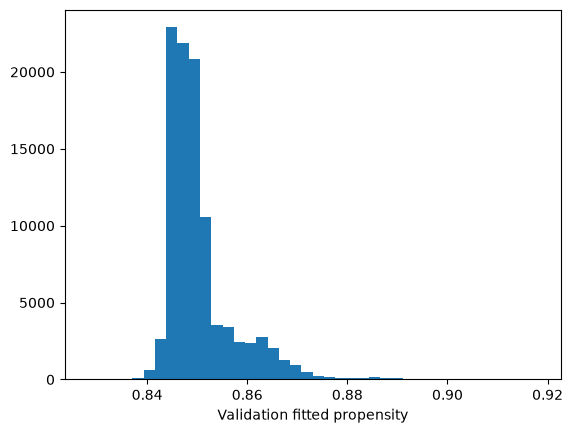

In [7]:
display(basic)
print('Validation propensity treatment prediction AUC:',roc_auc_score(T[v],eval_e))
print('Propensity range:',np.quantile(eval_e,[0,.01,.5,.99,1]))
print('Clipping share:',np.mean((eval_e<=.03)|(eval_e>=.97)))
basic.to_csv(OUT/'basic_effects.csv')
plt.hist(eval_e,bins=40);plt.xlabel('Validation fitted propensity');plt.show()

### ④ 판정
아래는 Validation 평균 차이에 대한 보조 진단입니다. 평균 효과가 양수여도 고객 간 효과 차이가 충분히 예측 가능하다는 뜻은 아닙니다.

In [8]:
print('Validation 평균 효과 진단:',verdict(*basic.loc['AIPW fitted e',['lo','hi']]))

Validation 평균 효과 진단: 지지


## STEP 5. 인과 ML과 교차 적합
### ① 가설·비교
H3의 고정 S 비교와 H4의 사전 후보 집합만 학습합니다. 각 모델은 두 입력 표현에서 같은 하이퍼파라미터·Train을 사용합니다.
### ② 원리
- S: Y=f(X,T)에서 T=1/0 예측 차이.
- T: μ₁(X)−μ₀(X).
- X: 각 군의 반사실 대입 차이를 학습한 뒤 e·τ_control+(1−e)·τ_treated로 결합.
- DR: 프로필 단위 3-fold 교차 적합으로 만든 AIPW 의사결과를 X에 회귀.
- DML: 교차 적합한 Y/T 잔차의 PLR 계수. **상수 효과 모형**이므로 일반적인 이질적 CATE/ATE와 구분.

범주형 인코더는 빈도 상위 63개와 기타로 총 64수준을 만듭니다. 이는 HGB의 max_bins=255 제한 안에 들어갑니다. 과거의 조기 중단 여부와 트리 설정도 바뀌므로 과거 실습 수치와 직접 비교하지 않습니다. **이번 수치형/범주형 짝끼리만 표현 효과를 비교**합니다.

In [9]:
models={}
for representation in ['numeric','categorical']:
    X=Xs[representation];cat_mask=None if representation=='numeric' else mask
    fitted=fit_candidates(X[tr],T[tr],Y[tr],cat_mask,SEED)
    for learner,model in fitted.items():models[representation+'/'+learner]=model
    print('fitted:',representation,flush=True)
advanced=fit_crossfit_dr(Xc[tr],T[tr],Y[tr],profile[tr],mask,SEED)
models['categorical/DR']=advanced['DR']
print('DML PLR constant-effect estimate:',advanced['DML'])
validation_scores={key:model.predict(Xs[key.split('/')[0]][v]) for key,model in models.items()}
val_rows={key:policy_stats(score,T[v],Y[v],np.full(len(v),.85),m0v,m1v,k=K,seed=SEED) for key,score in validation_scores.items()}
validation=pd.DataFrame(val_rows).T
selected=validation.PolicyGain.idxmax()
validation.to_csv(OUT/'validation_metrics.csv')
print('Validation-only selection frozen:',selected)
display(validation.sort_values('PolicyGain',ascending=False))
diagnostics=[]
for key,score in validation_scores.items():
    diagnostics.append({'model':key,'exact_zero_share':float(np.mean(score==0)),
        'unique_scores':len(np.unique(score)),'std':score.std(),'p05':np.quantile(score,.05),'p95':np.quantile(score,.95)})
diagnostics=pd.DataFrame(diagnostics).set_index('model')
display(diagnostics)
diagnostics.to_csv(OUT/'prediction_diagnostics.csv')
selection={'selected':selected,'criterion':'Validation PolicyGain@30%',
    'selected_at_utc':datetime.now(timezone.utc).isoformat(),'test_used':False}
(OUT/'selection.json').write_text(json.dumps(selection,indent=2))

fitted: numeric


fitted: categorical


DML PLR constant-effect estimate: {'estimate': 0.007102870775298237, 'se': 0.0007230070112497585, 'lo': 0.005685777033248711, 'hi': 0.008519964517347763}


Validation-only selection frozen: numeric/S


,PolicyValue,RandomValue,PolicyGain,AUUC,Qini,IncrementalRate,UpliftAt30,TargetFraction
numeric/S,0.047427,0.042025,0.005402,0.009858,0.004395,0.010331,0.029052,0.3
categorical/S,0.046927,0.042025,0.004902,0.010073,0.004610,0.010394,0.028287,0.3
numeric/X,0.046723,0.042025,0.004697,0.009131,0.003668,0.009743,0.028938,0.3
categorical/T,0.046678,0.042025,0.004652,0.008289,0.002825,0.008873,0.026040,0.3
numeric/T,0.046496,0.042025,0.004470,0.008942,0.003479,0.009312,0.027873,0.3
categorical/DR,0.046379,0.042025,0.004353,0.008967,0.003504,0.009304,0.028493,0.3
categorical/X,0.046050,0.042025,0.004024,0.008726,0.003262,0.009026,0.027603,0.3


,exact_zero_share,unique_scores,std,p05,p95
model,,,,,
numeric/S,0.0,11571,0.017718,0.000400,0.033450
numeric/T,0.0,24759,0.031275,-0.006082,0.055864
numeric/X,0.0,19805,0.027602,0.000315,0.049419
categorical/S,0.0,15040,0.015814,0.000168,0.029606
categorical/T,0.0,24322,0.041288,-0.015078,0.068544
categorical/X,0.0,22482,0.035331,-0.009245,0.059740
categorical/DR,0.0,15758,0.041317,-0.003063,0.057412


### ③ 결과·④ 해석
Validation 표에서 선택한 모델을 고정합니다. 0점 비율이 줄어든 것은 학습 행동의 변화이지 개선의 증명은 아닙니다. Validation에서 후보 차이가 작으면 선택이 불안정할 수 있으며, 단일 선택을 넘어선 안정성 연구는 별도 과제로 남깁니다. 여러 모델의 Test를 보고 선택을 바꾸지 않습니다.

## STEP 6. 새 Test에서 H3/H4 검증
### ① 고정 가설
H3: categorical/S − numeric/S > 0. H4: 고정 selected − random30 > 0.
### ② 평가 구현
상위 30%는 Test 특성에 대한 점수 순위로 정하고 결과 레이블로 정하지 않습니다. 동점은 결과·처치와 독립적인 고정 난수로 처리합니다. PolicyValue는 AIPW로 추정하며 같은 수의 고객을 무작위로 배정했을 때의 기대값을 뺀 것이 PolicyGain입니다. IPW 누적 gain 면적 AUUC와 무작위 직선 대비 면적 Qini도 출력합니다.

부트스트랩 구현은 각 고객의 재표집 횟수로 순위를 재구성합니다. 명시적인 행 복제와 동일함을 단위 테스트로 검증했습니다. 표본 30만 행을 매번 재정렬하지 않아 반복 계산을 줄입니다.

In [10]:
te=idx['test']
t,y=T[te],Y[te]
m0=mu0_model.predict(Xc[te]);m1=mu1_model.predict(Xc[te])
e0=np.full(len(te),.85)
efit=np.clip(propensity.predict_proba(small[te])[:,1],.03,.97)
test_scores={key:model.predict(Xs[key.split('/')[0]][te]) for key,model in models.items()}
metrics=pd.DataFrame({key:policy_stats(score,t,y,e0,m0,m1,k=K,seed=SEED) for key,score in test_scores.items()}).T
metrics.to_csv(OUT/'test_metrics.csv')
# Scores from a response model are only a descriptive comparator, not another selected learner.
contrast_scores={'typed_S':test_scores['categorical/S'],'numeric_S':test_scores['numeric/S'],
                 'selected':test_scores[selected],'response':m1}
contrasts={'H3':('typed_S','numeric_S'),'H4':('selected',None),
           'selected_vs_response_secondary':('selected','response')}
_,ci=bootstrap(contrast_scores,t,y,e0,m0,m1,contrasts,B=B,k=K,seed=SEED)
_,ci_sensitivity=bootstrap(contrast_scores,t,y,efit,m0,m1,{'H3':contrasts['H3'],'H4':contrasts['H4']},B=B,k=K,seed=SEED)
print('Holdout arm/event counts:')
display(pd.DataFrame({'treatment':t,'visit':y}).groupby('treatment').visit.agg(['count','sum','mean']))
display(metrics)
display(pd.DataFrame(ci).T)
print('Same frozen policies with fitted propensity sensitivity:')
display(pd.DataFrame(ci_sensitivity).T)
print('Test treatment prediction AUC:',roc_auc_score(t,efit))

Holdout arm/event counts:


,count,sum,mean
treatment,,,
0,45157,1715,0.037979
1,254896,12455,0.048863


,PolicyValue,RandomValue,PolicyGain,AUUC,Qini,IncrementalRate,UpliftAt30,TargetFraction
numeric/S,0.048055,0.042989,0.005066,0.010073,0.004708,0.010596,0.031915,0.3
numeric/T,0.047632,0.042989,0.004643,0.009495,0.004130,0.010024,0.031836,0.3
numeric/X,0.047620,0.042989,0.004631,0.009306,0.003941,0.009696,0.029647,0.3
categorical/S,0.047830,0.042989,0.004841,0.009785,0.004420,0.010010,0.030442,0.3
categorical/T,0.047036,0.042989,0.004047,0.008185,0.002819,0.008469,0.027797,0.3
categorical/X,0.046760,0.042989,0.003771,0.008278,0.002913,0.008540,0.027787,0.3
categorical/DR,0.046720,0.042989,0.003730,0.008417,0.003052,0.008730,0.027626,0.3


,estimate,lo,hi,verdict
H3,-0.000225,-0.001056,0.000493,판단 보류
H4,0.005066,0.003959,0.006221,지지
selected_vs_response_secondary,0.000109,-0.000544,0.000707,판단 보류


Same frozen policies with fitted propensity sensitivity:


,estimate,lo,hi,verdict
H3,-0.000244,-0.001109,0.000478,판단 보류
H4,0.005052,0.003894,0.006281,지지


Test treatment prediction AUC: 0.5107004041766043


### ③ 곡선과 세그먼트 결과
선택 모델의 10분위 그룹별 관측 차이를 출력하되, 여러 그룹 가운데 좋은 곳을 골라 새 가설을 검증했다고 주장하지 않습니다. 상위 그룹 대조군 사건 수가 적으면 결과가 흔들릴 수 있습니다. 누적 곡선은 IPW 기반이고 주 가설 정책 가치는 AIPW 기반이므로 값이 완전히 일치할 필요는 없습니다.

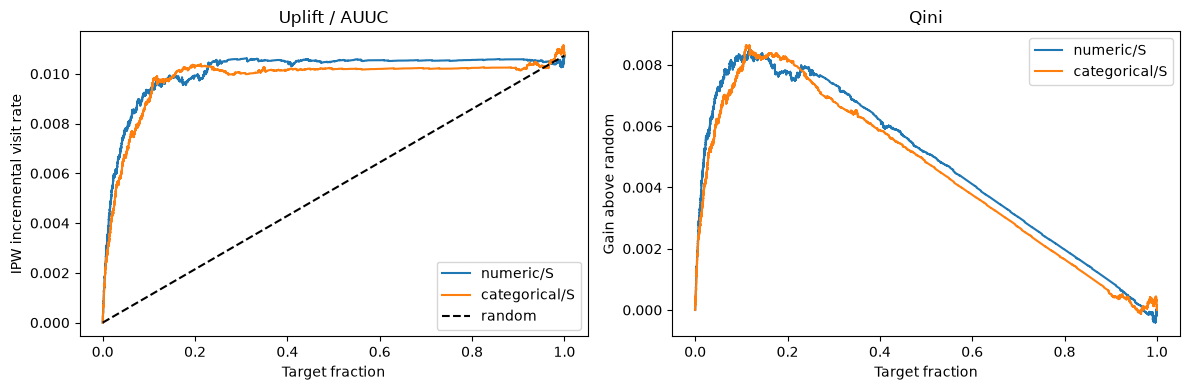

,rank_decile,n,control_n,control_visits,treated_visits,raw_visit_gap
0,1,30006,4049,867,7271,0.065990
1,2,30006,4494,365,2235,0.006386
2,3,30006,4608,167,1124,0.008014
3,4,30005,4480,29,138,-0.001067
4,5,30005,4680,59,338,0.000740
5,6,30005,4616,9,61,0.000453
6,7,30005,4533,3,16,-0.000034
7,8,30005,4555,2,15,0.000150
8,9,30005,4529,2,17,0.000226
9,10,30005,4613,212,1240,0.002877


In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
z=t*y/e0-(1-t)*y/(1-e0)
q=np.arange(len(te)+1)/len(te)
for key in dict.fromkeys(['numeric/S','categorical/S',selected]):
    tie=np.random.default_rng(SEED).random(len(te));order=np.lexsort((tie,-test_scores[key]))
    gain=np.r_[0,np.cumsum(z[order])/len(te)]
    axes[0].plot(q,gain,label=key);axes[1].plot(q,gain-q*z.mean(),label=key)
axes[0].plot(q,q*z.mean(),'k--',label='random')
axes[0].set(title='Uplift / AUUC',xlabel='Target fraction',ylabel='IPW incremental visit rate')
axes[1].set(title='Qini',xlabel='Target fraction',ylabel='Gain above random')
for ax in axes:ax.legend()
plt.tight_layout();plt.show()
order=np.lexsort((np.random.default_rng(SEED).random(len(te)),-test_scores[selected]))
segments=[]
for decile,group in enumerate(np.array_split(order,10),1):
    yy=y[group];tt=t[group];controls=yy[tt==0];treated=yy[tt==1]
    segments.append({'rank_decile':decile,'n':len(group),'control_n':len(controls),
        'control_visits':int(controls.sum()),'treated_visits':int(treated.sum()),
        'raw_visit_gap':treated.mean()-controls.mean()})
segments=pd.DataFrame(segments)
display(segments)
segments.to_csv(OUT/'holdout_deciles.csv',index=False)

### ④ 가설 판정과 실제 의미
아래 판정은 상수 e의 주 분석, 학습 e의 민감도 분석을 구분합니다. 민감도에서 방향이 바뀌면 강건한 개선으로 해석하지 않습니다. 방문 확률 차이 0.001은 0.1%p이며, 공개 벤치마크 1만 행당 약 10회의 방문 차이에 해당합니다. 실제 광고주에게 그대로 적용할 성과 예측은 아닙니다.

In [12]:
for name in ['H3','H4']:
    r=ci[name];s=ci_sensitivity[name]
    display(Markdown(f'**{name}: {r["verdict"]}** — 차이 {r["estimate"]*100:.4f}%p, '
        f'95% CI [{r["lo"]*100:.4f}, {r["hi"]*100:.4f}]%p. '
        f'학습 e 민감도 판정: {s["verdict"]}.'))
print('Selected-vs-response comparison is secondary and not multiplicity adjusted:',ci['selected_vs_response_secondary'])
summary=dict(study='criteo-data-first-v1',sample=sampling,split_counts=protocol['split_counts'],
    primary_hypothesis=H3,secondary_hypothesis=H4,selected=selected,H3=ci['H3'],H4=ci['H4'],
    sensitivity=ci_sensitivity,secondary_selected_vs_response=ci['selected_vs_response_secondary'],
    dml=advanced['DML'],test_arm_counts=[int((t==0).sum()),int((t==1).sum())],
    test_propensity_auc=float(roc_auc_score(t,efit)),scope='public-sample benchmark under additional causal assumptions',
    limitations=['outcome-dependent public subsampling','no real costs/margins/campaign IDs',
                 'conditional fitted-model bootstrap','single validation selection','rare category pooling'])
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str))
source_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ['shared/criteo/study.py','shared/criteo/models.py','shared/criteo/inference.py','scripts/build_criteo_study.py','references/ML_for_Causal_Inference.ipynb']}
source_notebook=json.loads((ROOT/'experiments/02_criteo/study.ipynb').read_text())
source_hashes['experiments/02_criteo/study.ipynb:cell_sources']=hashlib.sha256(json.dumps([cell['source'] for cell in source_notebook['cells']],ensure_ascii=False).encode()).hexdigest()
(OUT/'code_versions.json').write_text(json.dumps(source_hashes,ensure_ascii=False,indent=2))
display(pd.Series(summary))

**H3: 판단 보류** — 차이 -0.0225%p, 95% CI [-0.1056, 0.0493]%p. 학습 e 민감도 판정: 판단 보류.

**H4: 지지** — 차이 0.5066%p, 95% CI [0.3959, 0.6221]%p. 학습 e 민감도 판정: 지지.

Selected-vs-response comparison is secondary and not multiplicity adjusted: {'estimate': 0.00010902792811293138, 'lo': -0.0005443853062281342, 'hi': 0.0007074987583117642, 'verdict': '판단 보류'}


study                                                          criteo-data-first-v1
sample                            {'cache_key': 'criteo-fresh-v2-2716e1bf0fd157a...
split_counts                      {'discovery': 199536, 'train': 400351, 'valida...
primary_hypothesis                  범주형 S-Learner의 top30 정책 가치가 수치형 S-Learner보다 높다.
secondary_hypothesis              Validation에서 선택한 top30 정책이 random30 정책보다 방문을 높인다.
selected                                                                  numeric/S
H3                                {'estimate': -0.00022519002554668988, 'lo': -0...
H4                                {'estimate': 0.005065976690630065, 'lo': 0.003...
sensitivity                       {'H3': {'estimate': -0.0002436239904847065, 'l...
secondary_selected_vs_response    {'estimate': 0.00010902792811293138, 'lo': -0....
dml                               {'estimate': 0.007102870775298237, 'se': 0.000...
test_arm_counts                                                     [45157, 

In [13]:
conclusion_table=pd.DataFrame([
    {'question':'H3: categorical S minus numeric S',**ci['H3']},
    {'question':'H4: selected top30 minus random30',**ci['H4']},
    {'question':'Secondary: selected minus response ranking',**ci['selected_vs_response_secondary']}
]).set_index('question')
display(conclusion_table)
selected_value=metrics.loc[selected,'PolicyValue'];random_value=metrics.loc[selected,'RandomValue']
display(Markdown(f'이번 선택 모델은 **{selected}**입니다. 추정 방문율은 정책 {selected_value*100:.3f}%, '
    f'동일 인원 무작위 정책 {random_value*100:.3f}%입니다. '
    f'H4 차이는 공개표본 1만 행당 약 {ci["H4"]["estimate"]*10000:.1f}회 방문에 해당하며, '
    f'95% CI는 [{ci["H4"]["lo"]*10000:.1f}, {ci["H4"]["hi"]*10000:.1f}]회입니다.'))
display(Markdown('**해석의 경계:** 범주형 표현의 추가 효과(H3), 무작위 대비 개선(H4), '
    '일반 반응 예측 순위 대비 개선은 서로 다른 질문입니다. H4만 지지된다고 '
    '범주형 인코딩이나 인과 모델이 일반 반응 모델보다 우월하다고 결론 내리지 않습니다. '
    '이전 실습 대비 표본 크기·분할·학습 설정이 함께 바뀌었으므로 개선 원인을 한 요소로 귀속하지 않습니다.'))
conclusion_table.to_csv(OUT/'hypothesis_results.csv')

,estimate,lo,hi,verdict
question,,,,
H3: categorical S minus numeric S,-0.000225,-0.001056,0.000493,판단 보류
H4: selected top30 minus random30,0.005066,0.003959,0.006221,지지
Secondary: selected minus response ranking,0.000109,-0.000544,0.000707,판단 보류


이번 선택 모델은 **numeric/S**입니다. 추정 방문율은 정책 4.806%, 동일 인원 무작위 정책 4.299%입니다. H4 차이는 공개표본 1만 행당 약 50.7회 방문에 해당하며, 95% CI는 [39.6, 62.2]회입니다.

**해석의 경계:** 범주형 표현의 추가 효과(H3), 무작위 대비 개선(H4), 일반 반응 예측 순위 대비 개선은 서로 다른 질문입니다. H4만 지지된다고 범주형 인코딩이나 인과 모델이 일반 반응 모델보다 우월하다고 결론 내리지 않습니다. 이전 실습 대비 표본 크기·분할·학습 설정이 함께 바뀌었으므로 개선 원인을 한 요소로 귀속하지 않습니다.

## STEP 7. 결과를 바탕으로 다음 실험을 정하기

- H3가 지지되면: 입력 유형을 바로잡은 것이 고정 S 정책에서 유효했다는 범위로 해석합니다. 모든 학습기에서 동일하다고 확대하지 않습니다.
- H3가 판단 보류면: 타입 수정 자체는 타당해도 top63 병합·학습 설정·효과 이질성 때문에 성능 개선이 불명확할 수 있습니다. 결과를 보고 범주 수를 바꾼 뒤 같은 Test로 재검정하지 않습니다.
- H4가 지지되면: 이 공개본의 동일 인원 예산에서 무작위보다 나은 순위를 만들었다는 결과입니다. 실제 노출 비용·원 캠페인 증분 매출의 최적화는 아닙니다.
- H4가 판단 보류면: 표본을 늘린 것만으로 정책 개선이 입증되지 않은 것이므로 방문 예측 성능과 Uplift 순위의 차이를 더 점검해야 합니다.

다음 후보는 (1) top63 범주 병합의 정보 손실을 줄이는 사전 설계 실험, (2) 반복 분할에서 정책 선택 안정성, (3) 학습 표본 크기별 곡선입니다. 새 가설을 등록하고 아직 사용하지 않은 행에서 검증합니다. 익명화된 범주의 업무 의미를 복원하거나 임의로 ROAS를 계산하지 않습니다.

## 재현

`uv pip install --python .venv/bin/python -r requirements.txt` 후 `Python (causal_study .venv)` 커널에서 Run All.
CLI 실행: `.venv/bin/python scripts/execute_notebooks.py experiments/02_criteo/study.ipynb`.
원본은 `data/criteo`, 작은 결과 표·가설 등록·선택 기록은 `experiments/02_criteo/results`, 재생성 가능한 표본 캐시는 그 아래 `cache`에 저장됩니다. 이전 RetailHero 노트북을 실행할 필요가 없습니다.